In [351]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [352]:
def sigmoid(z):
  return 1/(1+np.exp(-z))

In [353]:
def fit_logistic_regression(X,y,learning_rate,iterations):
  num_samples,num_features = X.shape

  # Initialize parameters to zeros
  weights=np.zeros(num_features)
  bias=0

  # Gradient Descent
  for i in range(iterations):

    # Calculate continous linear combination and apply sigmoid
    linear_model = np.dot(X,weights)+bias
    y_predicted = sigmoid(linear_model)

    # compute gradients
    dw=np.dot(X.T,(y_predicted-y))
    db=np.sum(y_predicted - y)
    # Update parameters
    weights=weights-(learning_rate*dw)
    bias=bias-(learning_rate*db)

  return weights,bias

In [354]:
def predict_probabilities(X,weights,bias):
  linear_model = np.dot(X,weights)+bias
  return sigmoid(linear_model)

In [355]:
def predict_classes(X,weights,bias,threshold=0.5):
  probabilities=predict_probabilities(X,weights,bias)
  return np.where(probabilities>=threshold,1,0)

<Axes: >

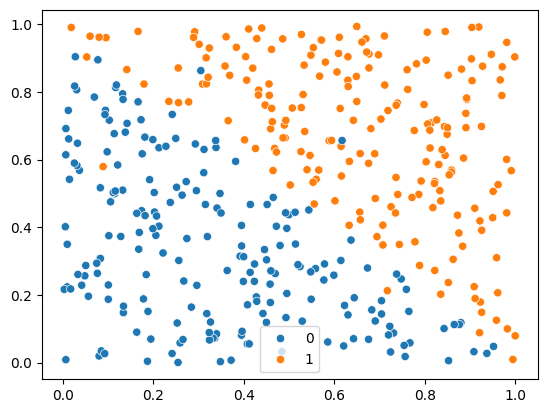

In [356]:
import random
np.random.seed(40)
X=np.random.rand(400,2)
y=np.where(X[:,0]+X[:,1]>1,1,0)
for i in range(5):
  j=random.randint(0,399)
  y[j]=(y[j]+1)%2
sns.scatterplot(x=X[:,0],y=X[:,1],hue=y)

In [357]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split

In [358]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=40)

In [359]:
lr=LogisticRegression()

In [360]:
lr.fit(X_train,y_train)

LogisticRegression()

In [361]:
y_pred=lr.predict(X_test)

In [362]:
accuracy_score(y_test,y_pred)

0.9625

In [363]:
(weights,bias)=fit_logistic_regression(X_train,y_train,0.01,1000)

In [364]:
y_pred=predict_classes(X_test,weights,bias)

In [365]:
accuracy_score(y_test,y_pred)

0.975